# Category Weighting in Sanskrit Compound Classification

CS 74 26F
Anagh Shukla

**Question:** How does category weighting affect Logistic Regression, linear SVC
and Multinomial Naive Bayes on Sanskrit compounds?

In [1]:
!git clone --depth 1 https://github.com/ashishgupta2598/SaCTI.git


Cloning into 'SaCTI'...
remote: Enumerating objects: 820, done.
remote: Counting objects: 100% (820/820), done.
remote: Compressing objects: 100% (624/624), done.
remote: Total 820 (delta 192), reused 791 (delta 192), pack-reused 0 (from 0)
Receiving objects: 100% (820/820), 22.64 MiB | 6.17 MiB/s, done.
Resolving deltas: 100% (192/192), done.
Updating files: 100% (786/786), done.


In [2]:
# Purpose: Read each dataset file into a list of examples.
# Each example stores the compound, its sentence context and its correct category.

from pathlib import Path

def load_sacti(filename):
    text = Path(filename).read_text(encoding="utf-8")
    examples = []

    for block in text.strip().split("\n\n"):
        rows = []
        for line in block.splitlines():
            if line.strip() and not line.startswith("#"):
                rows.append(line.split("\t"))
        if len(rows) == 0:
            continue

        # The final row in each block contains the target compound and category.
        target = rows[-1]
        assert target[6] == "0", "Unexpected target format"
        context_words = []
        for row in rows[:-1]:
            context_words.append(row[1])

        examples.append({
            "compound": target[1],
            "context": " ".join(context_words),
            "label": target[7]
        })
    return examples

folder = Path("SaCTI/data/coling/coarse")
train = load_sacti(folder / "train.conll")
dev = load_sacti(folder / "dev.conll")
test = load_sacti(folder / "test.conll")

print("Training examples:", len(train))
print("Validation examples:", len(dev))
print("Test examples:", len(test))
print("Example compound:", train[0]["compound"])
print("Example context:", train[0]["context"])
print("Example category:", train[0]["label"])


Training examples: 9356
Validation examples: 2338
Test examples: 2994
Example compound: मन्द-स्वरेण
Example context: वृद्धम् पश्यन् मन्द-स्वरेण अयम् तादृशम् किञ्चन अभाषत अहम् अपि
Example category: Tatpurusha


In [3]:
# Purpose: Make matching lists of compounds and correct categories for each split.
# Remove spaces at the ends and store equivalent visible characters consistently.
import unicodedata

def clean_text(text):
    # NFC gives equivalent visible characters a consistent computer representation.
    return unicodedata.normalize("NFC", text.strip())


def make_lists(data):
    compounds = []
    labels = []
    for example in data:
        compounds.append(clean_text(example["compound"]))
        labels.append(example["label"].strip())
    return compounds, labels

train_text, y_train = make_lists(train)
val_text, y_val = make_lists(dev)
test_text, y_test = make_lists(test)

print("Training compounds and labels:", len(train_text), len(y_train))
print("Validation compounds and labels:", len(val_text), len(y_val))
print("Test compounds and labels:", len(test_text), len(y_test))
print("Example:", train_text[0], y_train[0])


Training compounds and labels: 9356 9356
Validation compounds and labels: 2338 2338
Test compounds and labels: 2994 2994
Example: मन्द-स्वरेण Tatpurusha


In [4]:
# Purpose: Count training categories and inspect missing fields, duplicates and boundaries.
# Print the checks directly and save their summary.
from collections import Counter

training_counts = Counter(y_train)
print("Training category counts:", training_counts)

quality_rows = []
for name, data in [("Training", train), ("Validation", dev), ("Test", test)]:
    empty_fields = 0
    duplicates = 0
    unclear_boundaries = 0
    seen = set()

    for example in data:
        # Check whether a stored field is empty.
        for field in ["compound", "context", "label"]:
            if example[field].strip() == "":
                empty_fields += 1

        # Count repeated complete records within this split.
        record = (example["compound"], example["context"], example["label"])
        if record in seen:
            duplicates += 1
        seen.add(record)

        # Flag compounds that have a different structure from two nonempty parts.
        parts = example["compound"].split("-")
        if len(parts) != 2:
            unclear_boundaries += 1
        elif parts[0].strip() == "" or parts[1].strip() == "":
            unclear_boundaries += 1

    print("\n" + name)
    print("Empty fields:", empty_fields)
    print("Duplicate records:", duplicates)
    print("Compounds needing boundary inspection:", unclear_boundaries)
    quality_rows.append({
        "Split": name, "Empty fields": empty_fields,
        "Repeated complete records": duplicates,
        "Compounds needing boundary review": unclear_boundaries
    })

# Prepare the output folder and simple table display when they are first needed.
import pandas as pd

results_folder = Path("SaCTI_results")
results_folder.mkdir(exist_ok=True)


def show_table(table, title):
    print("\n" + title)
    print(table.round(4).to_string(index=False))


quality_table = pd.DataFrame(quality_rows)
quality_table.to_csv(results_folder / "data_checks.csv", index=False)


Training category counts: Counter({'Tatpurusha': 5460, 'Bahuvrihi': 2655, 'Dvandva': 808, 'Avyayibhava': 433})

Training
Empty fields: 0
Duplicate records: 0
Compounds needing boundary inspection: 8

Validation
Empty fields: 0
Duplicate records: 0
Compounds needing boundary inspection: 1

Test
Empty fields: 0
Duplicate records: 0
Compounds needing boundary inspection: 1


In [5]:
# Purpose: Count repeated compound spellings and identical records across splits.
# A familiar compound spelling can help a compound-only model even when its sentence differs.
split_names = ["Training", "Validation", "Test"]
split_texts = [train_text, val_text, test_text]
split_data = [train, dev, test]
spelling_sets = []
record_sets = []

for split_index in range(3):
    spelling_sets.append(set(split_texts[split_index]))
    records = set()
    for example in split_data[split_index]:
        records.add((clean_text(example["compound"]),
                     clean_text(example["context"]), example["label"].strip()))
    record_sets.append(records)

overlap_rows = []
for first in range(3):
    for second in range(first + 1, 3):
        shared_spellings = spelling_sets[first].intersection(spelling_sets[second])
        shared_records = record_sets[first].intersection(record_sets[second])
        affected_rows = 0
        for compound in split_texts[second]:
            if compound in shared_spellings:
                affected_rows += 1
        overlap_rows.append({
            "First split": split_names[first], "Second split": split_names[second],
            "Shared spellings": len(shared_spellings),
            "Identical labelled records": len(shared_records),
            "Affected examples in second split": affected_rows
        })
overlap_table = pd.DataFrame(overlap_rows)
show_table(overlap_table, "Overlap between the supplied splits")
overlap_table.to_csv(results_folder / "split_overlap.csv", index=False)



Overlap between the supplied splits
First split Second split  Shared spellings  Identical labelled records  Affected examples in second split
   Training   Validation               779                           0                               1258
   Training         Test                 0                           0                                  0
 Validation         Test                 0                           0                                  0


In [6]:
# Purpose: Turn compounds into numerical character-pattern features.
# Learn patterns and TF-IDF weights from training data, then reuse them for other splits.

from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    analyzer="char",
    ngram_range=(2, 5),
    lowercase=False
)
X_train = vectorizer.fit_transform(train_text)
X_val = vectorizer.transform(val_text)
X_test = vectorizer.transform(test_text)

# TF-IDF combines pattern occurrence with a training-based rarity weight and then scales each compound's numbers to a common numerical length.
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Training: (9356, 45929)
Validation: (2338, 45929)
Test: (2994, 45929)


In [7]:
# Purpose: Establish a reference classifier and define the primary evaluation score. This is the baseline, which always predicts the most common training category.

from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score

class_order = sorted(set(y_train))

def macro_f1(actual, predicted):
    return f1_score(actual, predicted, labels=class_order,
                    average="macro", zero_division=0)

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_val_predictions = baseline.predict(X_val)
baseline_val_f1 = macro_f1(y_val, baseline_val_predictions)
print("Baseline category:", baseline_val_predictions[0])
print("Baseline validation macro-F1:", round(baseline_val_f1, 4))


Baseline category: Tatpurusha
Baseline validation macro-F1: 0.1773


In [8]:
# Purpose: Fit one classifier using a chosen C/alpha and optional category weights.
# keeps the same model settings across tuning and weighting experiments.

from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

# Use the same workflow for the three independently fitted classifiers.
family_names = ["Logistic regression", "Linear SVC", "Naive Bayes"]
short_names = ["LR", "SVC", "NB"]


def train_model(family, parameter, weights=None):
    # LR uses C to control regularization and accepts a category-weight dictionary.
    if family == "Logistic regression":
        model = LogisticRegression(C=parameter, solver="lbfgs",
                                   class_weight=weights, max_iter=3000)
        model.fit(X_train, y_train)
        if model.n_iter_[0] >= model.max_iter:
            raise RuntimeError("LR reached its iteration limit. Increase max_iter.")

    # SVC has its own C and uses the same category-weight dictionary format.
    elif family == "Linear SVC":
        # Squared-hinge loss penalizes margin violations, including wrong predictions.
        # dual=False chooses the optimizer used in the earlier experiment.
        model = LinearSVC(C=parameter, loss="squared_hinge", dual=False,
                          class_weight=weights, max_iter=10000)
        model.fit(X_train, y_train)
        if model.n_iter_ >= model.max_iter:
            raise RuntimeError("SVC reached its iteration limit. Increase max_iter.")

    # NB uses alpha for smoothing and receives weights for individual examples.
    else:
        model = MultinomialNB(alpha=parameter)
        if weights is None:
            model.fit(X_train, y_train)
        else:
            # NB accepts one weight for each example in the training list.
            sample_weights = []
            for category in y_train:
                sample_weights.append(weights[category])
            model.fit(X_train, y_train, sample_weight=sample_weights)
    return model


In [9]:
# Purpose: Select C for LR/SVC and alpha for NB using validation macro-F1.
# Fit each candidate on training examples and record both training and validation results.

from sklearn.metrics import accuracy_score

parameter_values = {
    "Logistic regression": [0.001, 0.01, 0.1, 1, 10, 100, 1000],
    "Linear SVC": [0.001, 0.01, 0.1, 1, 10, 100, 1000],
    "Naive Bayes": [0.001, 0.01, 0.1, 1, 10]
}
parameter_names = {"Logistic regression": "C", "Linear SVC": "C", "Naive Bayes": "alpha"}
tuning_tables = {}
best_parameters = {}
unweighted_models = {}

for family in family_names:
    rows = []
    best_score = -1
    for parameter in parameter_values[family]:
        model = train_model(family, parameter)
        train_predictions = model.predict(X_train)
        val_predictions = model.predict(X_val)
        val_f1 = macro_f1(y_val, val_predictions)
        rows.append({
            "Parameter value": parameter,
            "Training macro-F1": macro_f1(y_train, train_predictions),
            "Validation macro-F1": val_f1,
            "Validation accuracy": accuracy_score(y_val, val_predictions)
        })
        print(family, parameter_names[family], parameter,
              "validation macro-F1:", round(val_f1, 4), flush=True)

        # Keep a candidate if its score exceeds the previous highest validation score.
        # Ties keep the first value in the ascending candidate list.
        if val_f1 > best_score:
            best_score = val_f1
            best_parameters[family] = parameter
            unweighted_models[family] = model

    tuning_tables[family] = pd.DataFrame(rows)
    show_table(tuning_tables[family], family + ": parameter search")
    tuning_tables[family].to_csv(results_folder / (family + "_tuning.csv"), index=False)


Logistic regression C 0.001 validation macro-F1: 0.1773
Logistic regression C 0.01 validation macro-F1: 0.1824
Logistic regression C 0.1 validation macro-F1: 0.5361
Logistic regression C 1 validation macro-F1: 0.7928
Logistic regression C 10 validation macro-F1: 0.8482
Logistic regression C 100 validation macro-F1: 0.8471
Logistic regression C 1000 validation macro-F1: 0.8436

Logistic regression: parameter search
 Parameter value  Training macro-F1  Validation macro-F1  Validation accuracy
           0.001             0.1843               0.1773               0.5496
           0.010             0.1916               0.1824               0.5526
           0.100             0.5497               0.5361               0.7190
           1.000             0.8551               0.7928               0.8409
          10.000             0.9746               0.8482               0.8661
         100.000             0.9775               0.8471               0.8631
        1000.000             0.9775 

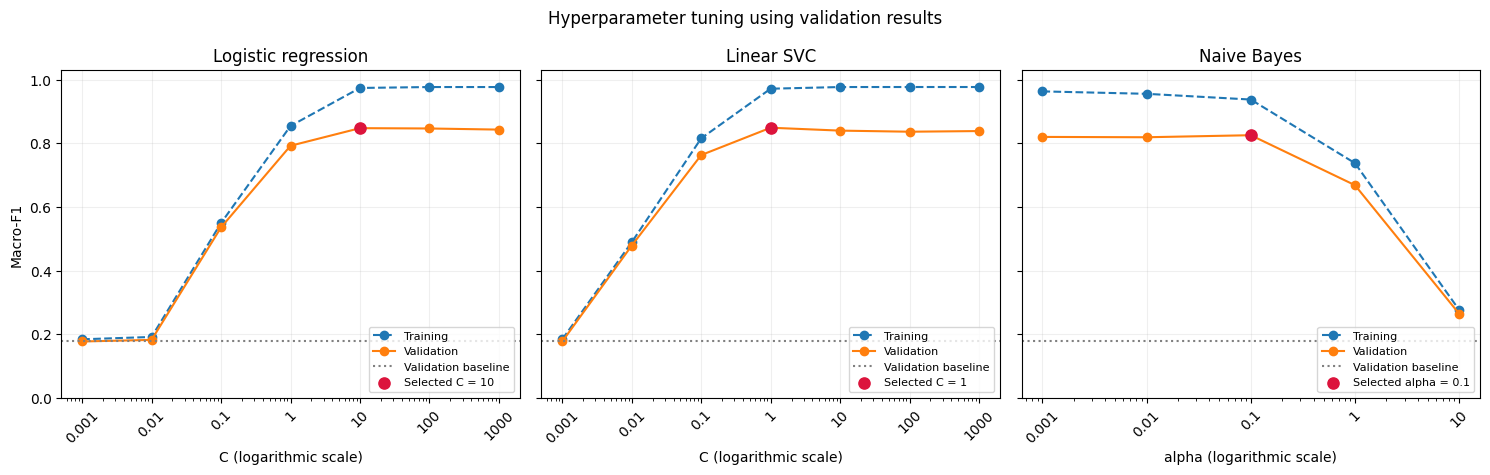

In [10]:
# Purpose: Show how validation macro-F1 determined each selected hyperparameter.
# Separate panels give C and alpha their own labelled axes.

import matplotlib.pyplot as plt

# Figure output: three tuning panels, each with training/validation curves and a selected point.
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
for family_index in range(3):
    family = family_names[family_index]
    ax = axes[family_index]
    table = tuning_tables[family]
    parameter = best_parameters[family]
    selected_row = table[table["Parameter value"] == parameter].iloc[0]
    ax.plot(table["Parameter value"], table["Training macro-F1"], "o--", label="Training")
    ax.plot(table["Parameter value"], table["Validation macro-F1"], "o-", label="Validation")
    ax.axhline(baseline_val_f1, color="gray", linestyle=":", label="Validation baseline")
    ax.scatter(parameter, selected_row["Validation macro-F1"], color="crimson", s=65,
               zorder=5, label="Selected " + parameter_names[family] + " = " + str(parameter))
    ax.set_xscale("log")
    ax.set_xticks(parameter_values[family])
    ax.set_xticklabels(parameter_values[family], rotation=45)
    ax.set_xlabel(parameter_names[family] + " (logarithmic scale)")
    ax.set_title(family)
    ax.set_ylim(0, 1.03)
    ax.legend(fontsize=8, loc="lower right")
    ax.grid(alpha=0.2)
axes[0].set_ylabel("Macro-F1")
fig.suptitle("Hyperparameter tuning using validation results")
fig.tight_layout()
fig.savefig(results_folder / "validation_hyperparameter_tuning.png", dpi=220, bbox_inches="tight")
plt.show()


## Weighting experiment

At 100% weighting, an example in category c receives weight N / (4 × n_c).
Here N is the training-set size and n_c is that category's training count.
Each category then contributes the same total training weight, N / 4.

At 25% weighting, apply one quarter of the change from example weight 1 to that
category's 100% weight. Use the same calculation for 50% and 75%.
The average weight across training examples stays 1 at every tested percentage.
The percentage describes this chosen weighting scale. Positive custom weights
can give a category more influence than the 100% setting gives it.

Hold C/alpha fixed at the values selected using 0% weighting. This investigates
the effect of weights at those settings. Joint tuning could give other results.


In [11]:
# Purpose: Calculate category weights for 0%, 25%, 50%, 75% and 100% weighting.
# Use training counts so that validation/test labels have no role in these calculations.

import numpy as np

weighting_strengths = [0, 0.25, 0.50, 0.75, 1]
weights_by_strength = {}
weight_rows = []

for strength in weighting_strengths:
    weights = {}
    total_weight = 0
    for category in class_order:
        # First calculate the weight that gives each category equal total influence.
        full_weight = len(y_train) / (len(class_order) * training_counts[category])
        # Then apply the chosen fraction of the change from weight 1 to that weight.
        weight = 1 + strength * (full_weight - 1)
        weights[category] = weight
        total_weight += training_counts[category] * weight
        weight_rows.append({
            "Weighting (%)": int(100 * strength), "Category": category,
            "Training examples": training_counts[category],
            "Weight per example": weight,
            "Total category weight": training_counts[category] * weight
        })
    assert np.isclose(total_weight / len(y_train), 1)
    weights_by_strength[strength] = weights

weight_table = pd.DataFrame(weight_rows)
show_table(weight_table, "Category weights used in training")
weight_table.to_csv(results_folder / "weight_definitions.csv", index=False)



Category weights used in training
 Weighting (%)    Category  Training examples  Weight per example  Total category weight
             0 Avyayibhava                433              1.0000                 433.00
             0   Bahuvrihi               2655              1.0000                2655.00
             0     Dvandva                808              1.0000                 808.00
             0  Tatpurusha               5460              1.0000                5460.00
            25 Avyayibhava                433              2.1005                 909.50
            25   Bahuvrihi               2655              0.9702                2576.00
            25     Dvandva                808              1.4737                1190.75
            25  Tatpurusha               5460              0.8571                4679.75
            50 Avyayibhava                433              3.2009                1386.00
            50   Bahuvrihi               2655              0.9405          

In [12]:
# Purpose: Fit the weighting variants and compare their validation macro-F1.
# Keep the C/alpha fixed, select one intermediate setting, and select the primary setting.
models = {}
validation_scores = {}
intermediate_strengths = {}
selected_strengths = {}
validation_rows = []

for family in family_names:
    models[family] = {}
    validation_scores[family] = {}
    best_score = -1
    best_intermediate_score = -1

    for strength in weighting_strengths:
        # Reuse the fitted 0% model from hyperparameter tuning.
        if strength == 0:
            model = unweighted_models[family]
        else:
            model = train_model(family, best_parameters[family], weights_by_strength[strength])
        models[family][strength] = model
        val_predictions = model.predict(X_val)
        val_f1 = macro_f1(y_val, val_predictions)
        validation_scores[family][strength] = val_f1
        validation_rows.append({
            "Classifier": family, "Weighting (%)": int(100 * strength),
            "Validation macro-F1": val_f1,
            "Validation accuracy": accuracy_score(y_val, val_predictions)
        })

        # Select the primary model using all five validation weighting scores.
        if val_f1 > best_score:
            best_score = val_f1
            selected_strengths[family] = strength

        # Also retain the intermediate setting with the highest validation macro-F1
        # among 25%, 50% and 75% for the planned weighting comparison.
        if strength in [0.25, 0.50, 0.75]:
            if val_f1 > best_intermediate_score:
                best_intermediate_score = val_f1
                intermediate_strengths[family] = strength

validation_table = pd.DataFrame(validation_rows)
show_table(validation_table, "Validation results at every weighting percentage")
validation_table.to_csv(results_folder / "validation_weighting.csv", index=False)



Validation results at every weighting percentage
         Classifier  Weighting (%)  Validation macro-F1  Validation accuracy
Logistic regression              0               0.8482               0.8661
Logistic regression             25               0.8479               0.8657
Logistic regression             50               0.8427               0.8648
Logistic regression             75               0.8449               0.8653
Logistic regression            100               0.8417               0.8627
         Linear SVC              0               0.8495               0.8666
         Linear SVC             25               0.8471               0.8648
         Linear SVC             50               0.8492               0.8657
         Linear SVC             75               0.8450               0.8653
         Linear SVC            100               0.8459               0.8661
        Naive Bayes              0               0.8260               0.8512
        Naive Bayes       

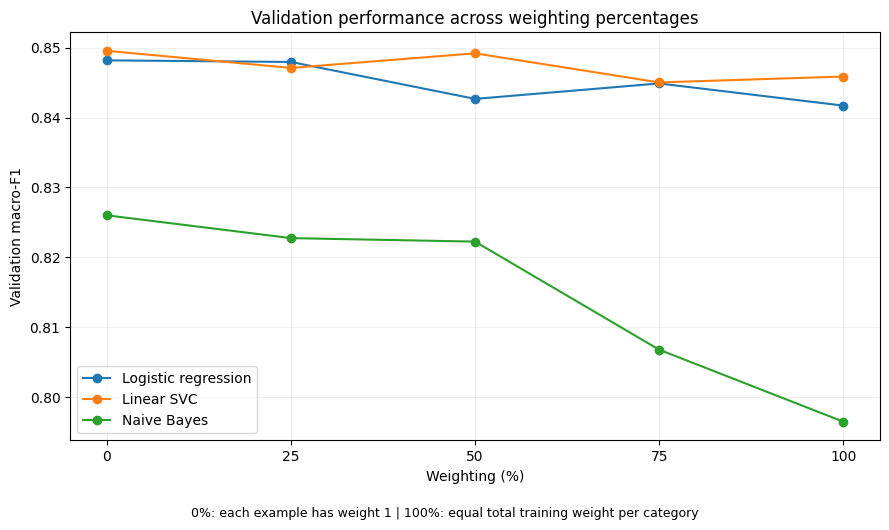

In [13]:
# Purpose: Show the effect of weighting on validation macro-F1 for all classifiers.
# The x-axis uses the five weighting percentages tested in this experiment.

# Figure output: one validation weighting curve per classifier.
fig, ax = plt.subplots(figsize=(9, 5.3))
for family in family_names:
    rows = validation_table[validation_table["Classifier"] == family]
    ax.plot(rows["Weighting (%)"], rows["Validation macro-F1"], "o-", label=family)
ax.set_xticks([0, 25, 50, 75, 100])
ax.set_xlabel("Weighting (%)")
ax.set_ylabel("Validation macro-F1")
ax.set_title("Validation performance across weighting percentages")
ax.legend()
ax.grid(alpha=0.2)
fig.text(0.5, 0.015, "0%: each example has weight 1 | 100%: equal total training weight per category",
         ha="center", fontsize=9)
fig.tight_layout(rect=[0, 0.05, 1, 1])
fig.savefig(results_folder / "validation_weighting.png", dpi=220, bbox_inches="tight")
plt.show()


In [14]:
# Purpose: Record the configurations selected through validation before calculating test metrics.
# Include 0%, one intermediate percentage and 100% for each classifier in the test comparison.
test_strengths = {}
selection_rows = []
for family in family_names:
    test_strengths[family] = [0, intermediate_strengths[family], 1]
    for strength in test_strengths[family]:
        selection_rows.append({
            "Classifier": family, "Parameter": parameter_names[family],
            "Parameter value": best_parameters[family],
            "Weighting (%)": int(100 * strength),
            "Validation macro-F1": validation_scores[family][strength],
            "Primary configuration": strength == selected_strengths[family]
        })
selection_table = pd.DataFrame(selection_rows)
show_table(selection_table, "Fixed configurations for the test evaluation")
selection_table.to_csv(results_folder / "selected_configurations.csv", index=False)



Fixed configurations for the test evaluation
         Classifier Parameter  Parameter value  Weighting (%)  Validation macro-F1  Primary configuration
Logistic regression         C             10.0              0               0.8482                   True
Logistic regression         C             10.0             25               0.8479                  False
Logistic regression         C             10.0            100               0.8417                  False
         Linear SVC         C              1.0              0               0.8495                   True
         Linear SVC         C              1.0             50               0.8492                  False
         Linear SVC         C              1.0            100               0.8459                  False
        Naive Bayes     alpha              0.1              0               0.8260                   True
        Naive Bayes     alpha              0.1             25               0.8228                  False


## Final test evaluation

We shall now evaluate the nine configurations chosen from above as well as the majority baseline on the SAME reserved test set. Outputs will be macro-F1, accuracy and category precision, recall and F1, as well as confusion matrices and ROC.

In [15]:
# Purpose: Measure test performance for every planned configuration.

from sklearn.metrics import classification_report

test_predictions = {}
test_reports = {}
overall_scores = {}
overall_rows = []
category_rows = []
prediction_table = pd.DataFrame({"Compound": test_text, "Actual category": y_test})

baseline_test_predictions = baseline.predict(X_test)
baseline_test_f1 = macro_f1(y_test, baseline_test_predictions)
baseline_test_accuracy = accuracy_score(y_test, baseline_test_predictions)
prediction_table["Majority baseline"] = baseline_test_predictions

for family in family_names:
    test_predictions[family] = {}
    test_reports[family] = {}
    overall_scores[family] = {}
    for strength in test_strengths[family]:
        predictions = models[family][strength].predict(X_test)
        test_predictions[family][strength] = predictions
        accuracy = accuracy_score(y_test, predictions)
        score = macro_f1(y_test, predictions)
        overall_scores[family][strength] = {"Accuracy": accuracy, "Macro-F1": score}
        overall_rows.append({"Classifier": family, "Weighting (%)": int(100 * strength),
                             "Test accuracy": accuracy, "Test macro-F1": score})
        prediction_table[family + " / " + str(int(100 * strength)) + "% weighting"] = predictions
        report = classification_report(y_test, predictions, labels=class_order,
                                       output_dict=True, zero_division=0)
        test_reports[family][strength] = report
        for category in class_order:
            category_rows.append({
                "Classifier": family, "Weighting (%)": int(100 * strength),
                "Category": category, "Precision": report[category]["precision"],
                "Recall": report[category]["recall"], "F1": report[category]["f1-score"],
                "Actual test examples": int(report[category]["support"])
            })

overall_table = pd.DataFrame(overall_rows)
category_table = pd.DataFrame(category_rows)
show_table(overall_table, "Final test performance")
show_table(category_table, "Test precision, recall and F1 by category")
print("Baseline test accuracy:", round(baseline_test_accuracy, 4))
print("Baseline test macro-F1:", round(baseline_test_f1, 4))
overall_table.to_csv(results_folder / "test_overall.csv", index=False)
category_table.to_csv(results_folder / "test_category_metrics.csv", index=False)
prediction_table.to_csv(results_folder / "test_predictions.csv", index=False, encoding="utf-8-sig")



Final test performance
         Classifier  Weighting (%)  Test accuracy  Test macro-F1
Logistic regression              0         0.7969         0.7547
Logistic regression             25         0.7946         0.7483
Logistic regression            100         0.7899         0.7466
         Linear SVC              0         0.7953         0.7510
         Linear SVC             50         0.7983         0.7526
         Linear SVC            100         0.7946         0.7463
        Naive Bayes              0         0.7428         0.6818
        Naive Bayes             25         0.7425         0.7057
        Naive Bayes            100         0.7261         0.6912

Test precision, recall and F1 by category
         Classifier  Weighting (%)    Category  Precision  Recall     F1  Actual test examples
Logistic regression              0 Avyayibhava     0.8793  0.7183 0.7907                   142
Logistic regression              0   Bahuvrihi     0.7831  0.7432 0.7626                   92

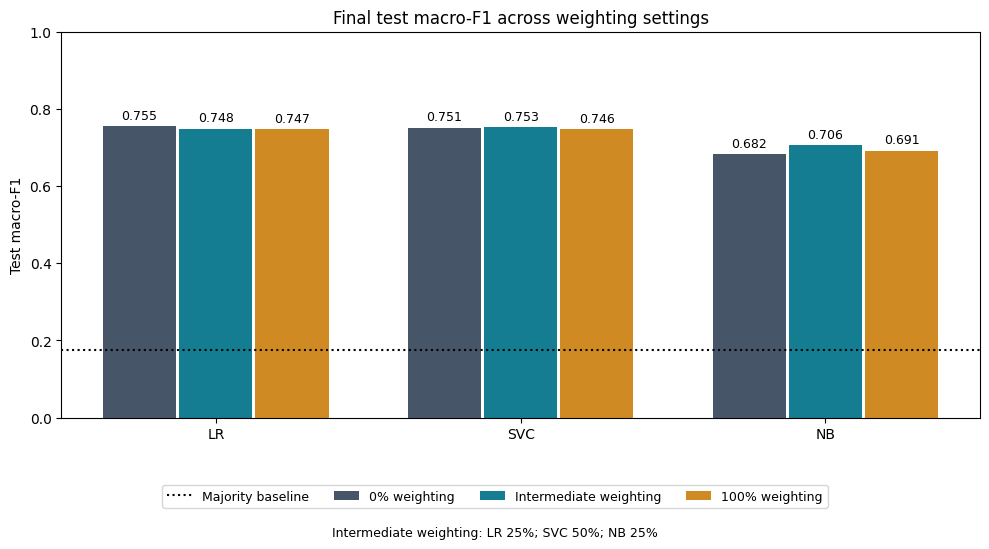

In [16]:
# Purpose: Compare test macro-F1 across classifiers and the three weighting groups.
# The intermediate group combines each classifier's validation-selected intermediate percentage.
variant_names = ["0% weighting", "Intermediate weighting", "100% weighting"]
variant_colors = ["#475569", "#147D92", "#D08A24"]
family_colors = ["#147D92", "#D08A24", "#8056A3"]
intermediate_caption = "Intermediate weighting: "
primary_caption = "Validation-selected weighting: "
for family_index in range(3):
    family = family_names[family_index]
    intermediate_caption += short_names[family_index] + " " + str(int(100 * intermediate_strengths[family])) + "%"
    primary_caption += short_names[family_index] + " " + str(int(100 * selected_strengths[family])) + "%"
    if family_index < 2:
        intermediate_caption += "; "
        primary_caption += "; "

# Figure output: one overall macro-F1 plot with three bars per classifier.
fig, ax = plt.subplots(figsize=(10, 5.5))
for variant_index in range(3):
    values = []
    for family in family_names:
        strength = test_strengths[family][variant_index]
        values.append(overall_scores[family][strength]["Macro-F1"])
    positions = np.arange(3) + (variant_index - 1) * 0.25
    bars = ax.bar(positions, values, width=0.24, color=variant_colors[variant_index],
                  label=variant_names[variant_index])
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)
ax.axhline(baseline_test_f1, color="black", linestyle=":", label="Majority baseline")
ax.set_xticks(np.arange(3), short_names)
ax.set_ylim(0, 1)
ax.set_ylabel("Test macro-F1")
ax.set_title("Final test macro-F1 across weighting settings")
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 0.055),
           ncol=4, fontsize=9)
fig.text(0.5, 0.015, intermediate_caption, ha="center", fontsize=9)
fig.tight_layout(rect=[0, 0.16, 1, 1])
fig.savefig(results_folder / "test_1_overall_macro_F1.png", dpi=220, bbox_inches="tight")
plt.show()


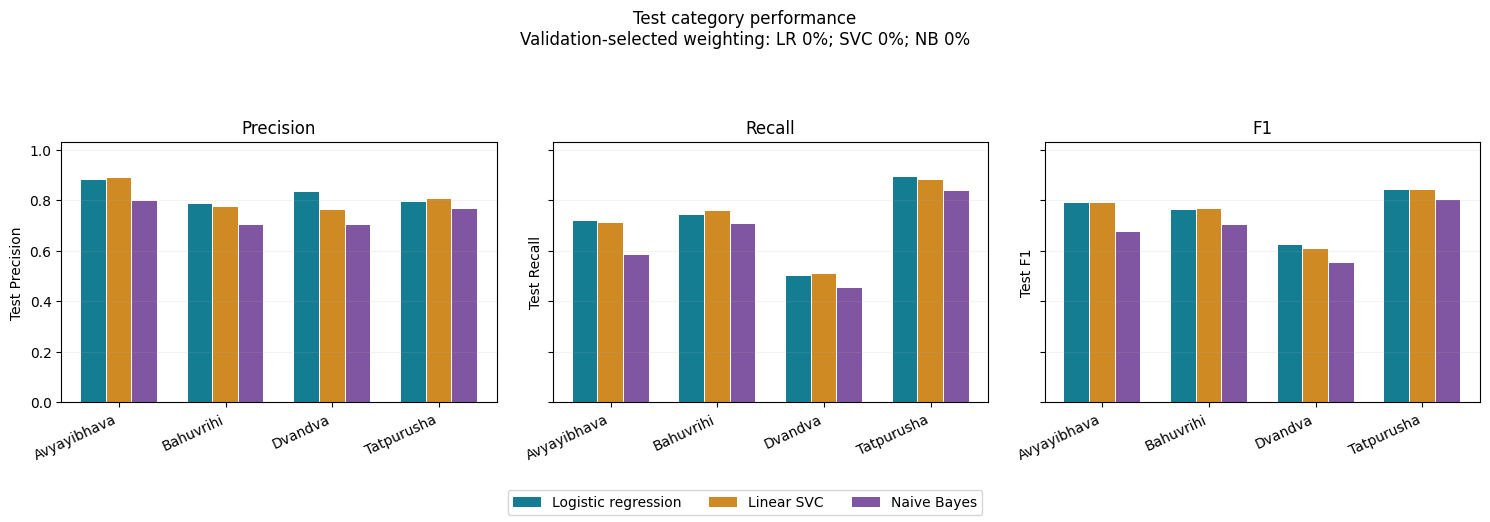

In [17]:
# Purpose: Compare all four categories for the three validation-selected classifiers.
# Use separate panels for precision, recall and F1 with the same category and color order.
metric_keys = ["precision", "recall", "f1-score"]
metric_labels = ["Precision", "Recall", "F1"]
category_positions = np.arange(len(class_order))

# Figure output: three panels, each containing all categories and classifiers.
fig, axes = plt.subplots(1, 3, figsize=(15, 5.2), sharey=True)
for metric_index in range(3):
    ax = axes[metric_index]
    for family_index in range(3):
        family = family_names[family_index]
        strength = selected_strengths[family]
        values = []
        for category in class_order:
            values.append(test_reports[family][strength][category][metric_keys[metric_index]])
        ax.bar(category_positions + (family_index - 1) * 0.24, values,
               width=0.23, color=family_colors[family_index], label=family)
    ax.set_xticks(category_positions, class_order, rotation=25, ha="right")
    ax.set_ylim(0, 1.03)
    ax.set_title(metric_labels[metric_index])
    ax.set_ylabel("Test " + metric_labels[metric_index])
    ax.grid(axis="y", alpha=0.15)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3)
fig.suptitle("Test category performance\n" + primary_caption, fontsize=12)
fig.tight_layout(rect=[0, 0.08, 1, 0.90])
fig.savefig(results_folder / "test_2_category_metrics.png", dpi=220, bbox_inches="tight")
plt.show()


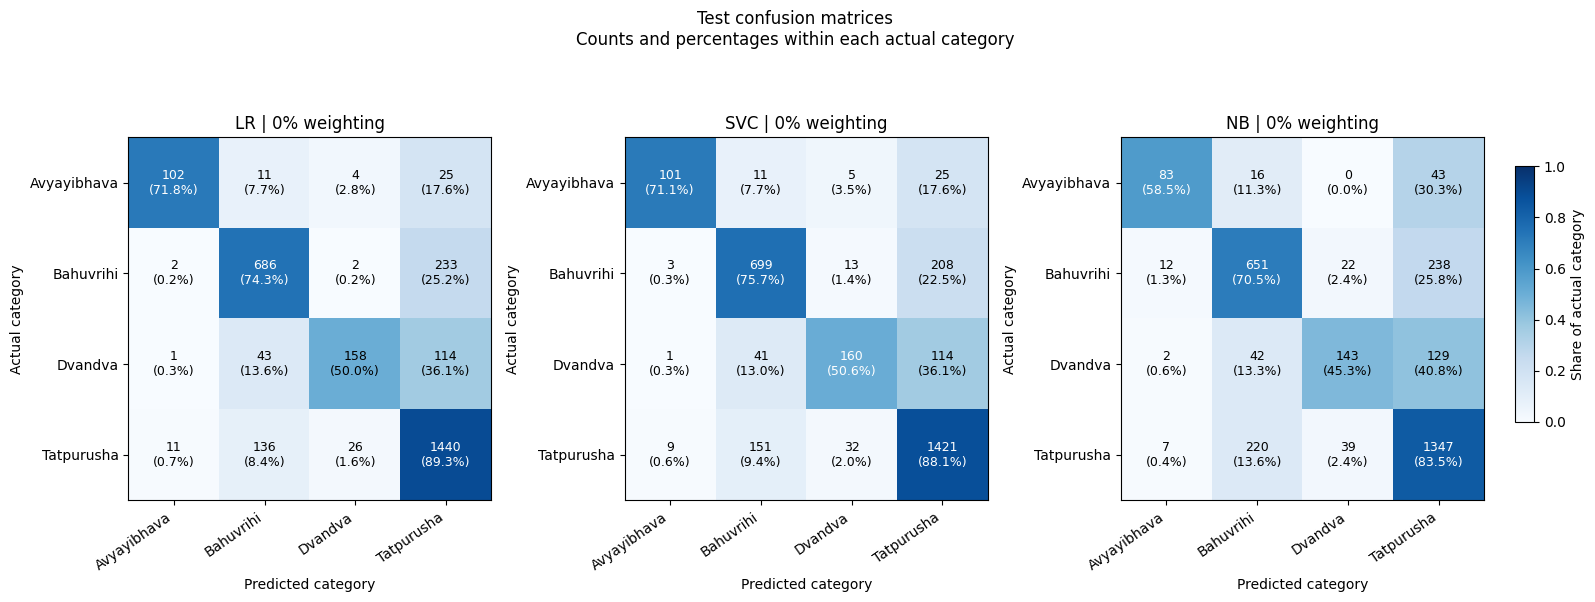

In [18]:
# Purpose: Show which categories each validation-selected classifier confuses.
# Rows show actual categories and columns show predictions. Each cell gives a count and row percentage.

from sklearn.metrics import confusion_matrix

# Figure output: one confusion-matrix panel per classifier, combined into one figure.
fig, axes = plt.subplots(1, 3, figsize=(16, 5.8))
for family_index in range(3):
    family = family_names[family_index]
    strength = selected_strengths[family]
    ax = axes[family_index]
    matrix = confusion_matrix(y_test, test_predictions[family][strength], labels=class_order)
    # All four categories occur in this test split. Divide by each actual category's total.
    row_shares = matrix / matrix.sum(axis=1, keepdims=True)
    image = ax.imshow(row_shares, cmap="Blues", vmin=0, vmax=1)
    for actual_index in range(len(class_order)):
        for predicted_index in range(len(class_order)):
            share = row_shares[actual_index, predicted_index]
            text_color = "black"
            if share > 0.5:
                text_color = "white"
            ax.text(predicted_index, actual_index,
                    f"{matrix[actual_index, predicted_index]}\n({100 * share:.1f}%)",
                    ha="center", va="center", fontsize=9, color=text_color)
    ax.set_xticks(category_positions, class_order, rotation=35, ha="right")
    ax.set_yticks(category_positions, class_order)
    ax.set_xlabel("Predicted category")
    ax.set_ylabel("Actual category")
    ax.set_title(short_names[family_index] + " | " + str(int(100 * strength)) + "% weighting")
    matrix_table = pd.DataFrame(matrix, index=class_order, columns=class_order)
    matrix_table.index.name = "Actual category / predicted category"
    matrix_table.to_csv(results_folder / (short_names[family_index] + "_test_confusion_counts.csv"))
fig.suptitle("Test confusion matrices\nCounts and percentages within each actual category")
fig.tight_layout(rect=[0, 0, 0.94, 0.90])
colorbar_ax = fig.add_axes([0.95, 0.27, 0.012, 0.44])
fig.colorbar(image, cax=colorbar_ax, label="Share of actual category")
fig.savefig(results_folder / "test_3_confusion_matrices.png", dpi=220, bbox_inches="tight")
plt.show()


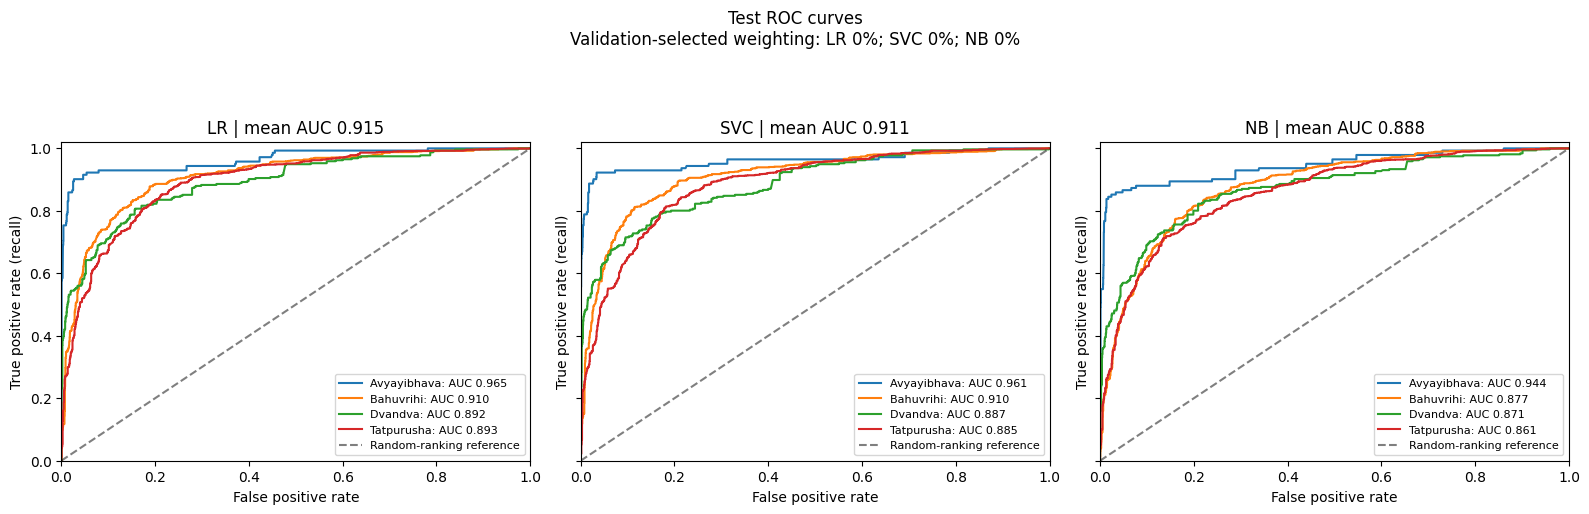


ROC AUC for the validation-selected classifiers
         Classifier  Weighting (%)      Category  Test ROC AUC
Logistic regression              0   Avyayibhava        0.9651
Logistic regression              0     Bahuvrihi        0.9096
Logistic regression              0       Dvandva        0.8919
Logistic regression              0    Tatpurusha        0.8931
Logistic regression              0 Macro average        0.9149
         Linear SVC              0   Avyayibhava        0.9606
         Linear SVC              0     Bahuvrihi        0.9100
         Linear SVC              0       Dvandva        0.8874
         Linear SVC              0    Tatpurusha        0.8847
         Linear SVC              0 Macro average        0.9107
        Naive Bayes              0   Avyayibhava        0.9440
        Naive Bayes              0     Bahuvrihi        0.8773
        Naive Bayes              0       Dvandva        0.8708
        Naive Bayes              0    Tatpurusha        0.8610
      

In [19]:
# Purpose: Evaluate how each selected classifier ranks one category against the other three.
# Move a threshold through its category scores and calculate recall and false-positive rate.
# LR/NB provide probabilities while SVC provides decision_function scores.

from sklearn.metrics import roc_curve, roc_auc_score

roc_rows = []

# Figure output: three ROC panels, each containing four category curves and their AUCs.
fig, axes = plt.subplots(1, 3, figsize=(16, 5.2), sharex=True, sharey=True)
for family_index in range(3):
    family = family_names[family_index]
    strength = selected_strengths[family]
    model = models[family][strength]
    ax = axes[family_index]
    if family == "Linear SVC":
        scores = model.decision_function(X_test)
    else:
        scores = model.predict_proba(X_test)

    category_aucs = []
    for category in class_order:
        column_index = list(model.classes_).index(category)
        # True marks an example belonging to this category; False marks another category.
        binary_labels = np.array(y_test) == category
        false_positive_rate, true_positive_rate, thresholds = roc_curve(
            binary_labels, scores[:, column_index])
        category_auc = roc_auc_score(binary_labels, scores[:, column_index])
        category_aucs.append(category_auc)
        roc_rows.append({"Classifier": family, "Weighting (%)": int(100 * strength),
                         "Category": category, "Test ROC AUC": category_auc})
        ax.plot(false_positive_rate, true_positive_rate,
                label=f"{category}: AUC {category_auc:.3f}")

    mean_auc = float(np.mean(category_aucs))
    roc_rows.append({"Classifier": family, "Weighting (%)": int(100 * strength),
                     "Category": "Macro average", "Test ROC AUC": mean_auc})
    ax.plot([0, 1], [0, 1], "k--", alpha=0.5, label="Random-ranking reference")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate (recall)")
    ax.set_title(short_names[family_index] + f" | mean AUC {mean_auc:.3f}")
    ax.legend(fontsize=8, loc="lower right")
fig.suptitle("Test ROC curves\n" + primary_caption, fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.90])
fig.savefig(results_folder / "test_4_ROC.png", dpi=220, bbox_inches="tight")
plt.show()
roc_table = pd.DataFrame(roc_rows)
show_table(roc_table, "ROC AUC for the validation-selected classifiers")
roc_table.to_csv(results_folder / "test_ROC_AUC.csv", index=False)


In [20]:
# Purpose: Count frequent errors and review five fixed examples from the selected SVC.
# An error-pair count is the number with the named actual label and predicted label.

confusion_rows = []
for family in family_names:
    for strength in test_strengths[family]:
        matrix = confusion_matrix(y_test, test_predictions[family][strength], labels=class_order)
        for actual_index in range(len(class_order)):
            actual_total = int(matrix[actual_index].sum())
            for predicted_index in range(len(class_order)):
                if actual_index != predicted_index:
                    count = int(matrix[actual_index, predicted_index])
                    confusion_rows.append({
                        "Classifier": family, "Weighting (%)": int(100 * strength),
                        "Actual category": class_order[actual_index],
                        "Predicted category": class_order[predicted_index],
                        "Misclassified test examples": count,
                        "Actual-category examples with this error (%)": 100 * count / actual_total
                    })
confusion_pairs = pd.DataFrame(confusion_rows).sort_values(
    "Misclassified test examples", ascending=False)
show_table(confusion_pairs.head(15), "The 15 error pairs with the largest example counts")
confusion_pairs.to_csv(results_folder / "test_error_pairs.csv", index=False)

review_rows = []
svc_predictions = test_predictions["Linear SVC"][selected_strengths["Linear SVC"]]
for example_index in range(len(y_test)):
    if svc_predictions[example_index] != y_test[example_index]:
        review_rows.append({
            "Test example number": example_index + 1, "Compound": test_text[example_index],
            "Sentence context": test[example_index]["context"],
            "Actual category": y_test[example_index], "Predicted category": svc_predictions[example_index]
        })
    if len(review_rows) == 5:
        break
error_review = pd.DataFrame(review_rows)
show_table(error_review, "First five SVC errors in test-file order")
error_review.to_csv(results_folder / "five_SVC_errors.csv", index=False, encoding="utf-8-sig")
# This fixed sample illustrates mistakes.



The 15 error pairs with the largest example counts
         Classifier  Weighting (%) Actual category Predicted category  Misclassified test examples  Actual-category examples with this error (%)
        Naive Bayes            100      Tatpurusha          Bahuvrihi                          292                                       18.1029
        Naive Bayes              0       Bahuvrihi         Tatpurusha                          238                                       25.7855
Logistic regression              0       Bahuvrihi         Tatpurusha                          233                                       25.2438
        Naive Bayes             25      Tatpurusha          Bahuvrihi                          224                                       13.8872
        Naive Bayes             25       Bahuvrihi         Tatpurusha                          222                                       24.0520
        Naive Bayes              0      Tatpurusha          Bahuvrihi         

In [21]:
# Purpose: Optional demonstration of predictions for a hyphen-separated Devanagari compound.
# Reuse the fitted models and learned features to illustrate the prediction interface.

def predict_compound(compound):
    compound = clean_text(compound)
    if compound == "":
        raise ValueError("Enter a hyphen-separated Devanagari compound.")
    features = vectorizer.transform([compound])
    if features.nnz == 0:
        print("This input has zero character patterns in the learned vocabulary.")
    rows = []
    for family in family_names:
        for strength in test_strengths[family]:
            prediction = models[family][strength].predict(features)[0]
            rows.append({"Classifier": family, "Weighting (%)": int(100 * strength),
                         "Compound": compound, "Predicted category": prediction})
    return pd.DataFrame(rows)

# Demonstration: use one training compound to show how to call the function.
# Performance is measured in the earlier test tables and figures.
# To try another input, replace train_text[0] with a quoted, hyphen-separated compound.
show_table(predict_compound(train_text[0]), "Example compound predictions")



Example compound predictions
         Classifier  Weighting (%)    Compound Predicted category
Logistic regression              0 मन्द-स्वरेण         Tatpurusha
Logistic regression             25 मन्द-स्वरेण         Tatpurusha
Logistic regression            100 मन्द-स्वरेण         Tatpurusha
         Linear SVC              0 मन्द-स्वरेण         Tatpurusha
         Linear SVC             50 मन्द-स्वरेण         Tatpurusha
         Linear SVC            100 मन्द-स्वरेण         Tatpurusha
        Naive Bayes              0 मन्द-स्वरेण         Tatpurusha
        Naive Bayes             25 मन्द-स्वरेण         Tatpurusha
        Naive Bayes            100 मन्द-स्वरेण         Tatpurusha


In [22]:
# Purpose: Package the result tables and six figures for download or submission.
import shutil

archive_path = shutil.make_archive("SaCTI_results", "zip", root_dir=results_folder)
print("Results folder:", results_folder.resolve())
print("Results ZIP:", archive_path)

Results folder: /content/SaCTI_results
Results ZIP: /content/SaCTI_results.zip
